In [1]:
%load_ext autoreload
%autoreload 2


import os 
import numpy as np
import matplotlib.pyplot as plt

from src.config_presets.tools.get_config import get_config
from src.visualization.plot_slices import plot_slices

config = get_config('Xerostomia_model', testMode=True)


src/config_presets/Base_config.yaml
src/config_presets/Xerostomia_model.yaml
src/config_presets/testMode_config.yaml


In [2]:
source_dir = r"/share/projectline_hnc_modelling/Users/Daniel MacRae/Z. Other stuff/PRIMA_data_checks/HNC_Base_checks"

path_to_export_folder = r"/share/projectline_hnc_modelling/Users/Daniel MacRae/Z. Other stuff/PRIMA_data_checks/HNC_Base_plots"

if not os.path.exists(path_to_export_folder):
    os.makedirs(path_to_export_folder)
    
# List all the files in the source directory
files = os.listdir(source_dir)

In [3]:
def plot_numpy_files_for_one_patient(config, path_to_folder):
    #if os.path.isdir(path_to_folder):
    rtdose_files = [
        filename for filename in os.listdir(path_to_folder)
        if filename.startswith("RTDOSE")
    ]
    #print(f"{patient_id}: {len(rtdose_files)} RTDOSE files")

    row_dicts = []

    for idx in range(len(rtdose_files)):
        CT = np.load(os.path.join(path_to_folder, f"CT_{idx}.npy"))
        RTDOSE = np.load(os.path.join(path_to_folder, f"RTDOSE_{idx}.npy"))
        RTSTRUCT = np.load(os.path.join(path_to_folder, f"RTSTRUCT_{idx}.npy"))

        CT = np.clip(CT, -200, 400)  # Clip CT values to the range [-1024, 3071]
        RTDOSE = np.clip(RTDOSE, 0, 8000)  # Clip RTDOSE values to the range [0, 8000]

        row_dicts.extend([
            {
                "Label" : f'RTDOSE_{idx}', 
                "ct" : CT.copy(), 
                "rtdose" : RTDOSE, 
                "segmentation_map" : RTSTRUCT
            }, {
                "Label" : 'CT',
                'ct' : CT.copy()
            }, {
                "Label" : 'RTDOSE',
                "rtdose" : RTDOSE,
            },{
                "Label" : 'segmentation_map',
                "segmentation_map" : RTSTRUCT
            }
        ])

    # nr_images = 9
    # nr_slices = CT.shape[0]
    # slice_indicies = np.linspace(0, nr_slices - 1, num=nr_images)
    # slice_indicies = np.unique(slice_indicies.astype(int))
    
    # print(slice_indicies)
    # slice_indicies = [90, 91, 92, 93, 94, 95, 96, 97, 98, 99]
    slice_indicies = [10, 20, 30, 40, 50, 60, 70, 80, 90]
    fig, axs = plot_slices(config, row_dicts, slice_indicies)

    #return fig, axs
    return fig

    


In [4]:
patients_ID_list = os.listdir(source_dir)
#patients_ID_list = ['7822891']

for patient_id   in patients_ID_list:
    patient_dir = os.path.join(source_dir, patient_id)
    # if os.path.isdir(patient_dir):
    #     print(f"Processing patient: {patient_id}")
    #     plot_slices(patient_dir, config)
    #print(os.listdir(patient_dir)   )
    for date_folder in os.listdir(patient_dir):
        date_folder_path = os.path.join(patient_dir, date_folder)
        if os.path.isdir(date_folder_path):
            #print(f"Processing date folder: {date_folder}")
            fig = plot_numpy_files_for_one_patient(config, date_folder_path)

            if len(os.listdir(patient_dir)) > 1:
                filename = f"{patient_id}_{date_folder}.png"
            else:
                filename = f"{patient_id}.png"
            

            savefig_path = os.path.join(path_to_export_folder, filename)
            fig.savefig(savefig_path, dpi=300, bbox_inches='tight')

            plt.close('all')  # Close the figure to free up memory

In [81]:
patient_id

'2376970'

In [16]:
print(date_folder_path)

/share/projectline_hnc_modelling/Users/Daniel MacRae/Z. Other stuff/PRIMA_data_checks/HNC_Base_checks/9577277/20210601


In [25]:
# do the same for the PRIMA preprocessed patients

PRIMA_source_dir = r"/share/projectline_hnc_modelling/Users/Daniel MacRae/Z. Other stuff/PRIMA_data_checks/PRIMA_preprocessed_stride_rt"

PRIMA_path_to_export_folder = r"/share/projectline_hnc_modelling/Users/Daniel MacRae/Z. Other stuff/PRIMA_data_checks/PRIMA_plots"
if not os.path.exists(PRIMA_path_to_export_folder):
    os.makedirs(PRIMA_path_to_export_folder)

for patient_id in os.listdir(PRIMA_source_dir): # check only those in the Wouter source file
    PRIMA_patient_dir = os.path.join(PRIMA_source_dir, patient_id)
    if not os.path.isdir(PRIMA_patient_dir): 
        continue

    CT = np.load(os.path.join(PRIMA_patient_dir, "CT.npy"))
    RTDOSE = np.load(os.path.join(PRIMA_patient_dir, "RTDOSE.npy"))
    RTSTRUCT = np.load(os.path.join(PRIMA_patient_dir, "RTSTRUCT.npy"))

    CT = np.clip(CT, -200, 400)  # Clip CT values to the range [-1024, 3071]
    RTDOSE = np.clip(RTDOSE, 0, 8000)  # Clip RTDOSE values to the range [0, 8000]

    row_dicts = ([
        {
            "Label" : f'All inputs', 
            "ct" : CT.copy(), 
            "rtdose" : RTDOSE, 
            "segmentation_map" : RTSTRUCT
        }, {
            "Label" : 'CT',
            'ct' : CT.copy()
        }, {
            "Label" : 'RTDOSE',
            "rtdose" : RTDOSE,
        },{
            "Label" : 'segmentation_map',
            "segmentation_map" : RTSTRUCT
        }
    ])
    
    # nr_images = 9
    # nr_slices = CT.shape[0]
    # slice_indicies = np.linspace(0, nr_slices - 1, num=nr_images)
    # slice_indicies = np.unique(slice_indicies.astype(int))
    
    # print(slice_indicies)
    # slice_indicies = [90, 91, 92, 93, 94, 95, 96, 97, 98, 99]
    slice_indicies = [10, 20, 30, 40, 50, 60, 70, 80, 90]
    fig, axs = plot_slices(config, row_dicts, slice_indicies)

    filename = f"{patient_id}.png"
    savefig_path = os.path.join(PRIMA_path_to_export_folder, filename)
    fig.savefig(savefig_path, dpi=300, bbox_inches='tight')

    plt.close('all')

In [18]:
os.listdir(PRIMA_source_dir)

FileNotFoundError: [Errno 2] No such file or directory: '/share/projectline_hnc_modelling\\Users\\Daniel MacRae\\Z. Other stuff\\PRIMA_data_checks\\PRIMA_preprocessed_stride_rt'

[10, 20, 30, 40, 50, 60, 70, 80, 90]


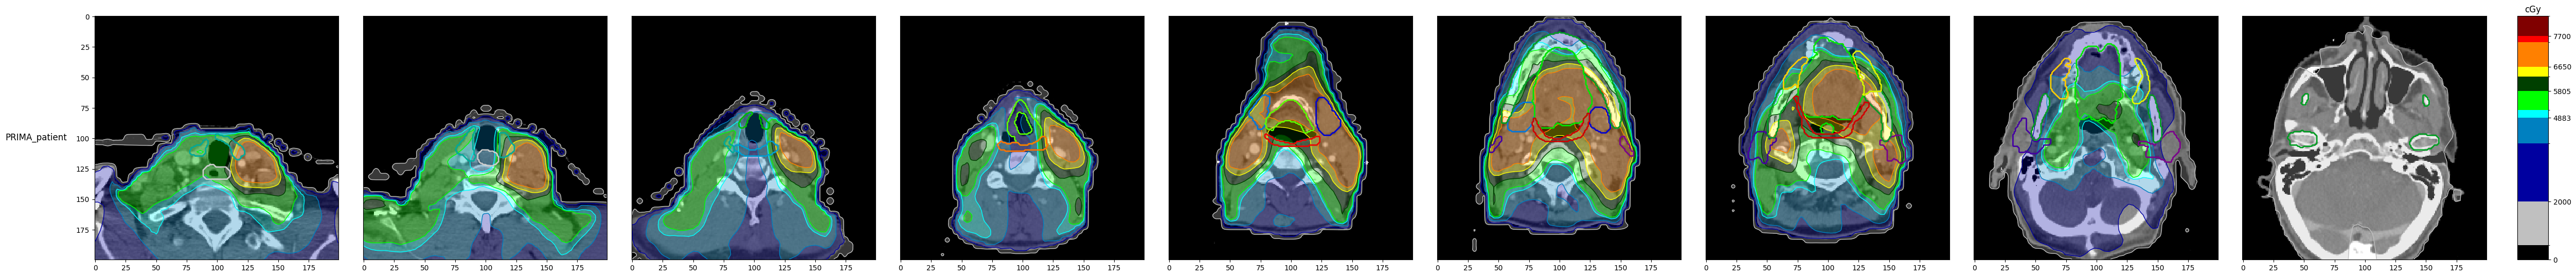

In [ ]:
# test a PRIMA patient
PRIMA_patient_dir = r"/share/projectline_hnc_modelling/PRI2MA/all_data_preprocessed_2025/dataset_full/7822891"
CT = np.load(os.path.join(PRIMA_patient_dir, "ct.npy"))[0]
RTDOSE = np.load(os.path.join(PRIMA_patient_dir, "rtdose.npy"))[0]
RTSTRUCT = np.load(os.path.join(PRIMA_patient_dir, "segmentation_map.npy"))[0]

row_dicts = [
    {"Label" : f'PRIMA_patient', 
     "ct" : CT, 
     "rtdose" : RTDOSE, 
     "segmentation_map" : RTSTRUCT},
]

slice_indicies = [90, 91, 92, 93, 94, 95, 96, 97, 98, 99]
nr_images = 9
nr_slices = CT.shape[0]
slice_indicies = np.linspace(0, nr_slices - 1, num=nr_images)
slice_indicies = np.unique(slice_indicies.astype(int))

slice_indicies = [10, 20, 30, 40, 50, 60, 70, 80, 90]

print(slice_indicies)
fig, axs = plot_slices(config, row_dicts, slice_indicies)

plt.close('all')  # Close all previous figures